# Phases IV–VI: K-Means Clustering, Agglomerative Clustering & Comparative Analysis
**Author:** Ahmed Younas — MS Artificial Intelligence, Semester 1  
**Scope:** Full Augmented ($N=150$) & Genuine-Only ($N=54$), Config A (18 feats) vs. Config B (14 feats), `SEED=42`. Target columns (Q6–Q8, `impact_category`) are strictly excluded before fitting.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import dendrogram, linkage

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

current_dir = Path.cwd()
if (current_dir / "data" / "processed").exists():
    proc_dir = current_dir / "data" / "processed"
elif (current_dir / "Digital_Device_Usage_Analysis" / "data" / "processed").exists():
    proc_dir = current_dir / "Digital_Device_Usage_Analysis" / "data" / "processed"
elif (current_dir / "full_150_corrected_features.csv").exists():
    proc_dir = current_dir
else:
    proc_dir = current_dir.parent / "data" / "processed"

df_150 = pd.read_csv(proc_dir / "full_150_corrected_features.csv")
df_54 = pd.read_csv(proc_dir / "genuine_54_corrected_features.csv")

config_a = [
    'gender_encoded',
    'year_First year', 'year_Second year', 'year_Third year', 'year_Fourth year', 'year_Other',
    'daily_device_hours', 'check_frequency',
    'phone_with_family', 'conversation_interruption', 'social_complaints', 'stay_away_difficulty',
    'activity_Communication and messaging', 'activity_Educational activities',
    'activity_Online gaming', 'activity_Other', 'activity_Social media',
    'activity_Watching videos and entertainment'
]
config_b = [
    'gender_encoded',
    'year_First year', 'year_Second year', 'year_Third year', 'year_Fourth year', 'year_Other',
    'social_conflict_score', 'digital_dependency_score',
    'activity_Communication and messaging', 'activity_Educational activities',
    'activity_Online gaming', 'activity_Other', 'activity_Social media',
    'activity_Watching videos and entertainment'
]

forbidden = {'academic_impact_avg', 'impact_category', 'impact_encoded', 'record_id', 'data_source', 'Timestamp'}
assert not forbidden.intersection(config_a) and not forbidden.intersection(config_b)
print(f"Loaded Full 150: {df_150.shape} | Genuine 54: {df_54.shape} | Target isolation verified.")

Loaded Full 150: (150, 24) | Genuine 54: (54, 24) | Target isolation verified.


## 1. K-Means Clustering ($K=2$ to $6$)
Standardize features with `StandardScaler`, evaluate WCSS (Inertia) and Silhouette Score, and inspect Elbow curves.

In [2]:
datasets = [('Full 150 Augmented', df_150), ('Genuine 54 Only', df_54)]
configs = [('Config A (Atomic, 18 feats)', config_a), ('Config B (Composite, 14 feats)', config_b)]
scaler = StandardScaler()
class_names = ['Low Impact', 'Moderate Impact', 'High Impact']

km_rows = []
for ds_name, df in datasets:
    for cfg_name, feats in configs:
        X_sc = scaler.fit_transform(df[feats])
        y_true = df['impact_category'].values
        for k in range(2, 7):
            km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED).fit(X_sc)
            km_rows.append({
                'Dataset': ds_name, 'Config': cfg_name, 'K': k,
                'Inertia': round(km.inertia_, 2),
                'Silhouette': round(silhouette_score(X_sc, km.labels_), 4),
                'ARI': round(adjusted_rand_score(y_true, km.labels_), 4),
                'NMI': round(normalized_mutual_info_score(y_true, km.labels_), 4)
            })
df_km = pd.DataFrame(km_rows)
df_km

,Dataset,Config,K,Inertia,Silhouette,ARI,NMI
0,Full 150 Augmented,"Config A (Atomic, 18 feats)",2,2439.37,0.1201,-0.0008,0.0046
1,Full 150 Augmented,"Config A (Atomic, 18 feats)",3,2245.43,0.1519,0.0078,0.0057
2,Full 150 Augmented,"Config A (Atomic, 18 feats)",4,2072.65,0.1495,0.0625,0.0720
3,Full 150 Augmented,"Config A (Atomic, 18 feats)",5,1925.26,0.1761,0.0159,0.0294
4,Full 150 Augmented,"Config A (Atomic, 18 feats)",6,1724.23,0.2020,0.0784,0.0743
5,Full 150 Augmented,"Config B (Composite, 14 feats)",2,1842.21,0.1649,0.0001,0.0050
6,Full 150 Augmented,"Config B (Composite, 14 feats)",3,1644.67,0.1904,0.0061,0.0043
7,Full 150 Augmented,"Config B (Composite, 14 feats)",4,1481.84,0.2169,0.0625,0.0720
8,Full 150 Augmented,"Config B (Composite, 14 feats)",5,1332.88,0.2232,0.0195,0.0273
9,Full 150 Augmented,"Config B (Composite, 14 feats)",6,1171.84,0.2199,0.0148,0.0329


<cell>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


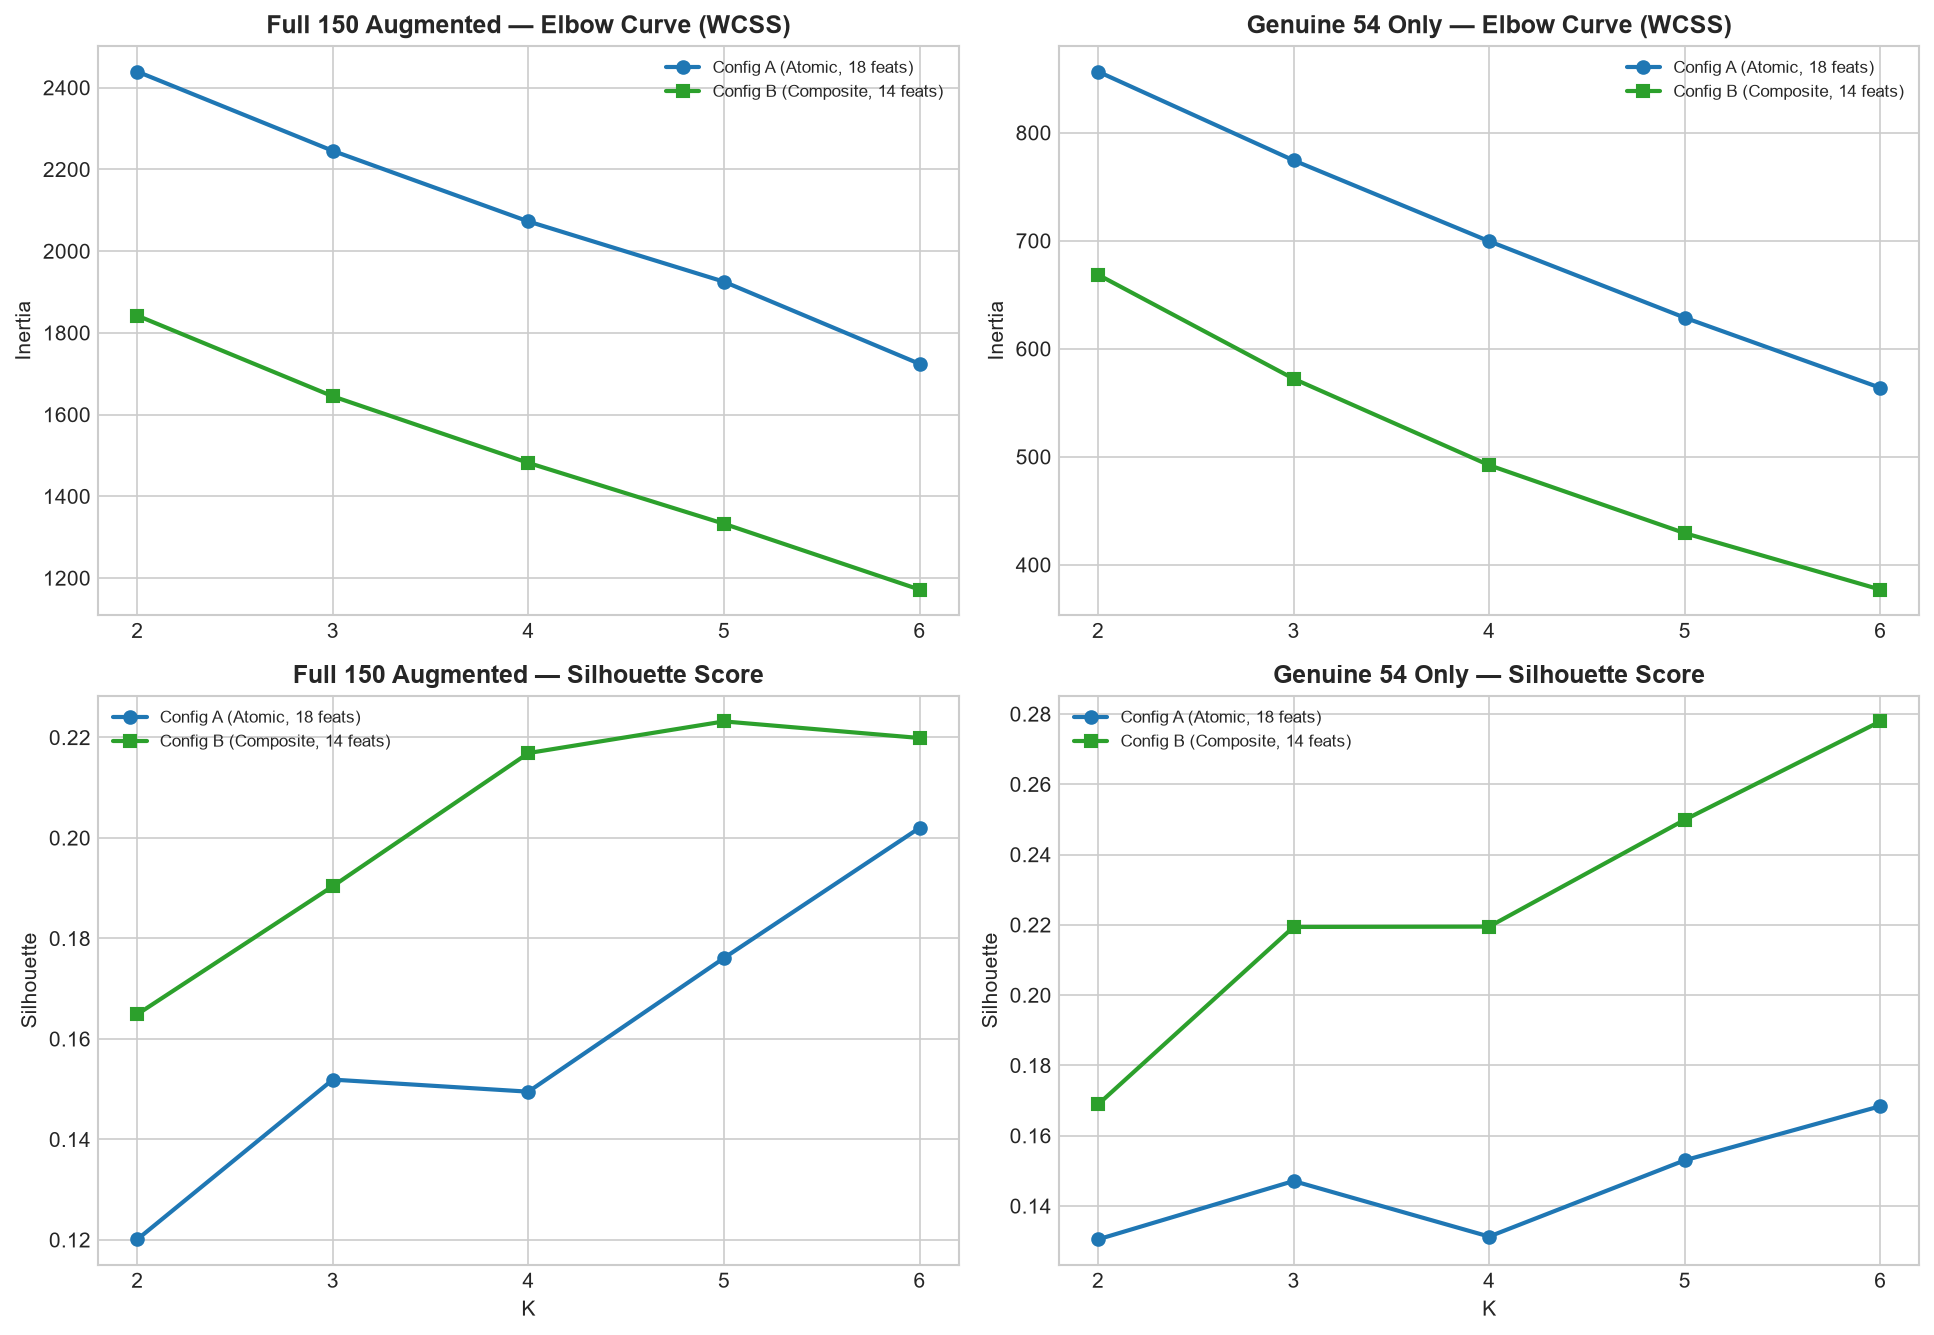

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for c_idx, (ds_name, _) in enumerate(datasets):
    sub = df_km[df_km['Dataset'] == ds_name]
    for cfg_name, color, mkr in [('Config A (Atomic, 18 feats)', '#1f77b4', 'o'), ('Config B (Composite, 14 feats)', '#2ca02c', 's')]:
        s = sub[sub['Config'] == cfg_name].sort_values('K')
        axes[0, c_idx].plot(s['K'], s['Inertia'], label=cfg_name, color=color, marker=mkr, linewidth=2)
        axes[1, c_idx].plot(s['K'], s['Silhouette'], label=cfg_name, color=color, marker=mkr, linewidth=2)
    axes[0, c_idx].set_title(f"{ds_name} — Elbow Curve (WCSS)", fontweight='bold')
    axes[0, c_idx].set_ylabel("Inertia")
    axes[1, c_idx].set_title(f"{ds_name} — Silhouette Score", fontweight='bold')
    axes[1, c_idx].set_ylabel("Silhouette")
    axes[1, c_idx].set_xlabel("K")
    for r in [0, 1]:
        axes[r, c_idx].set_xticks(range(2, 7))
        axes[r, c_idx].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. K-Means Post-Processing: 2D PCA Clusters, Centroids & Unexpected Observations ($K=3$, Config B)
Visualize discovered clusters in 2D PCA space, report descriptive cluster means (without circular $p$-values), dominant actual class per cluster, and negative-silhouette boundary observations.

<cell>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


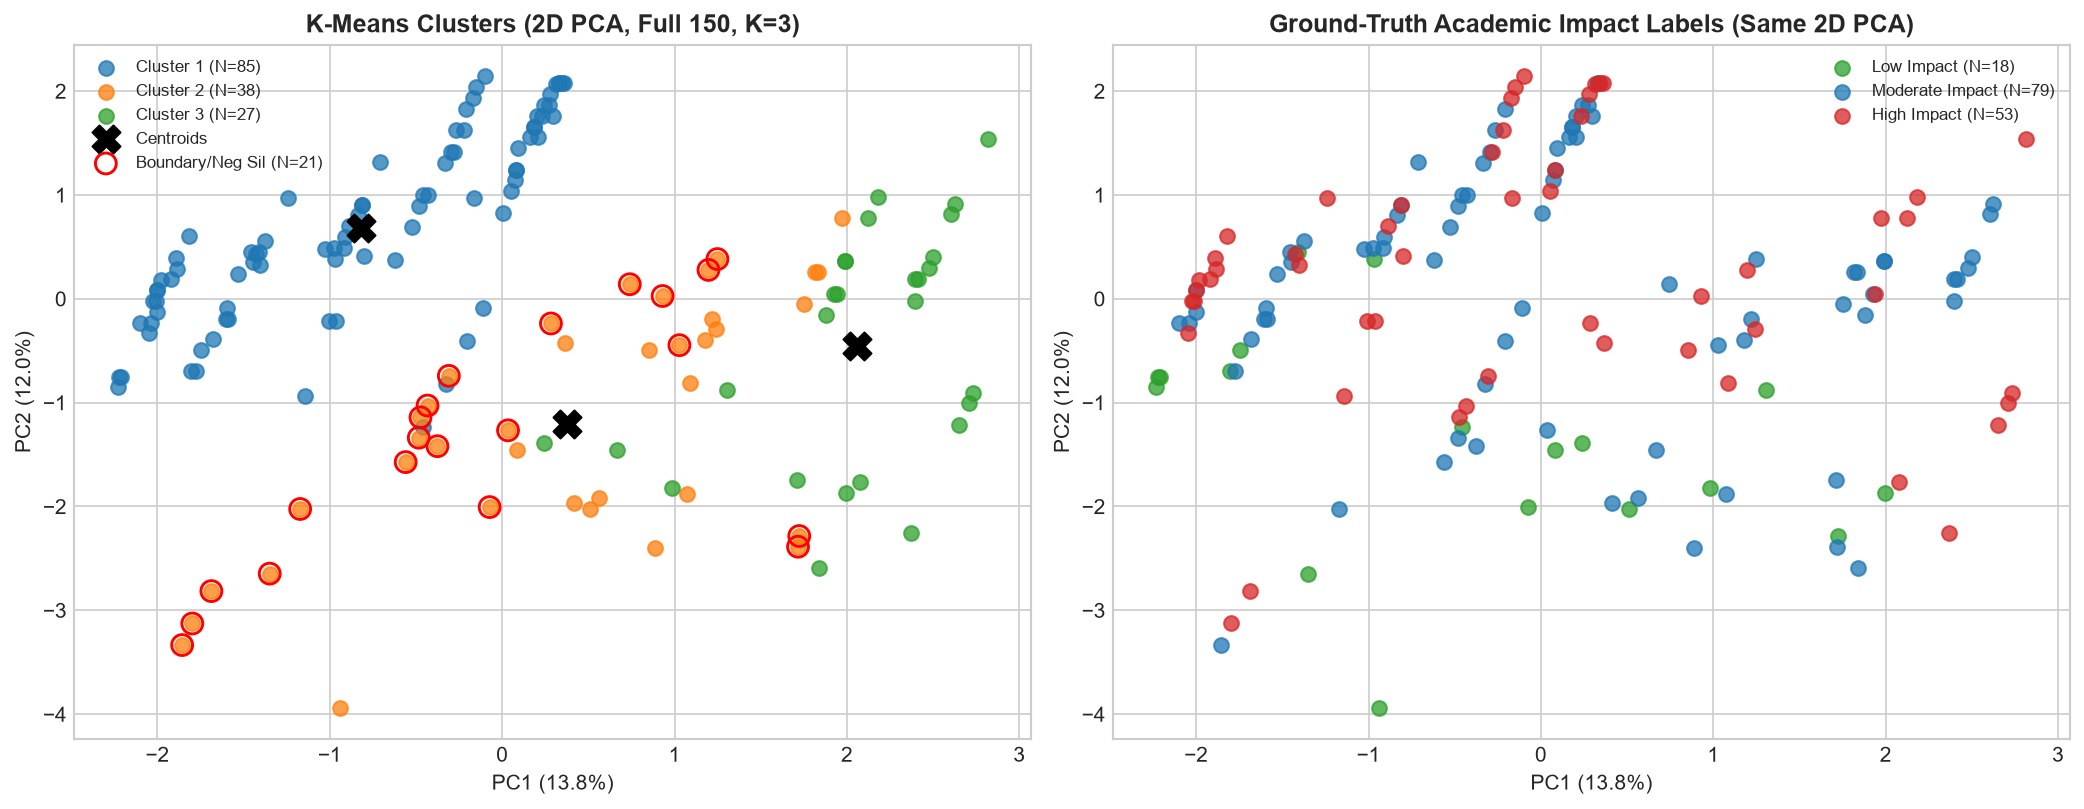

In [4]:
X_sc_150 = scaler.fit_transform(df_150[config_b])
km3 = KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=SEED)
km_lbls = km3.fit_predict(X_sc_150) + 1
sil_vals = silhouette_samples(X_sc_150, km_lbls - 1)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_sc_150)
cent_pca = pca.transform(km3.cluster_centers_)
var_exp = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
c_cols = {1: '#1f77b4', 2: '#ff7f0e', 3: '#2ca02c'}
for cid in [1, 2, 3]:
    m = km_lbls == cid
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], c=c_cols[cid], label=f"Cluster {cid} (N={m.sum()})", alpha=0.75, s=50)
axes[0].scatter(cent_pca[:, 0], cent_pca[:, 1], c='black', marker='X', s=180, label='Centroids', zorder=5)
neg_m = sil_vals < 0
axes[0].scatter(X_pca[neg_m, 0], X_pca[neg_m, 1], facecolors='none', edgecolors='red', s=100, linewidths=1.4, label=f"Boundary/Neg Sil (N={neg_m.sum()})")
axes[0].set_title("K-Means Clusters (2D PCA, Full 150, K=3)", fontweight='bold')
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)"); axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)"); axes[0].legend(fontsize=8)

imp_cols = {'Low Impact': '#2ca02c', 'Moderate Impact': '#1f77b4', 'High Impact': '#d62728'}
for cls in class_names:
    m = df_150['impact_category'].values == cls
    axes[1].scatter(X_pca[m, 0], X_pca[m, 1], c=imp_cols[cls], label=f"{cls} (N={m.sum()})", alpha=0.75, s=50)
axes[1].set_title("Ground-Truth Academic Impact Labels (Same 2D PCA)", fontweight='bold')
axes[1].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)"); axes[1].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
df_prof = df_150.copy()
df_prof['Cluster'] = km_lbls
profile_vars = ['daily_device_hours', 'check_frequency', 'social_conflict_score', 'digital_dependency_score', 'stay_away_difficulty']
means_tbl = df_prof.groupby('Cluster')[profile_vars].mean().round(2)
means_tbl.insert(0, 'Count', df_prof['Cluster'].value_counts().sort_index())

ct = pd.crosstab(df_prof['Cluster'], df_prof['impact_category']).reindex(columns=class_names, fill_value=0)
means_tbl['Dominant Class'] = ct.idxmax(axis=1)
print("=== K-Means Cluster Counts, Descriptive Means & Dominant Actual Class (Full 150, K=3) ===")
display(means_tbl)
print("\n=== Contingency Table (Cluster vs. Actual Impact) ===")
display(ct)

# Flag negative-silhouette / boundary observations
df_unexp = df_prof[['data_source', 'daily_device_hours', 'check_frequency', 'social_conflict_score', 'digital_dependency_score', 'impact_category', 'Cluster']].copy()
df_unexp['Silhouette'] = np.round(sil_vals, 4)
flagged = df_unexp[df_unexp['Silhouette'] < 0].sort_values('Silhouette')
print(f"\n=== Sample Unexpected / Boundary Observations (Total Negative Silhouette: {len(flagged)}) ===")
display(flagged.head(6))

=== K-Means Cluster Counts, Descriptive Means & Dominant Actual Class (Full 150, K=3) ===
         Count  daily_device_hours  check_frequency  social_conflict_score  digital_dependency_score  stay_away_difficulty   Dominant Class
Cluster                                                                                                                                    
1           85                3.51             3.92                   2.96                      3.49                  3.06  Moderate Impact
2           38                3.66             3.58                   3.01                      3.38                  2.89  Moderate Impact
3           27                3.59             4.19                   3.02                      3.49                  2.70  Moderate Impact

=== Contingency Table (Cluster vs. Actual Impact) ===
impact_category  Low Impact  Moderate Impact  High Impact
Cluster                                                  
1                         8            

## 3. Agglomerative Hierarchical Clustering (Single, Complete, Average, Ward)
Evaluate all **4 required linkage methods** across $K \in [2, 6]$, plot dendrograms, and compare cluster size balance and dominant actual classes at $K=3$.

In [6]:
agg_rows = []
for ds_name, df in datasets:
    for cfg_name, feats in configs:
        X_sc = scaler.fit_transform(df[feats])
        y_true = df['impact_category'].values
        for link in ['single', 'complete', 'average', 'ward']:
            for k in range(2, 7):
                lbls = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_sc)
                agg_rows.append({
                    'Dataset': ds_name, 'Config': cfg_name, 'Linkage': link, 'K': k,
                    'Silhouette': round(silhouette_score(X_sc, lbls), 4),
                    'ARI': round(adjusted_rand_score(y_true, lbls), 4),
                    'NMI': round(normalized_mutual_info_score(y_true, lbls), 4)
                })
df_agg = pd.DataFrame(agg_rows)
print("=== Agglomerative Comparison at K=3 (Config B, All 4 Linkages) ===")
display(df_agg[(df_agg['K'] == 3) & (df_agg['Config'].str.contains('Config B'))])

=== Agglomerative Comparison at K=3 (Config B, All 4 Linkages) ===
               Dataset                          Config   Linkage  K  Silhouette     ARI     NMI
21  Full 150 Augmented  Config B (Composite, 14 feats)    single  3      0.2491  0.0332  0.0351
26  Full 150 Augmented  Config B (Composite, 14 feats)  complete  3      0.2056  0.0398  0.0250
31  Full 150 Augmented  Config B (Composite, 14 feats)   average  3      0.2491  0.0332  0.0351
36  Full 150 Augmented  Config B (Composite, 14 feats)      ward  3      0.1499  0.0177  0.0516
61     Genuine 54 Only  Config B (Composite, 14 feats)    single  3      0.3169  0.0389  0.0287
66     Genuine 54 Only  Config B (Composite, 14 feats)  complete  3      0.2210  0.0674  0.1173
71     Genuine 54 Only  Config B (Composite, 14 feats)   average  3      0.3169  0.0389  0.0287
76     Genuine 54 Only  Config B (Composite, 14 feats)      ward  3      0.2298  0.0285  0.0297


<cell>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


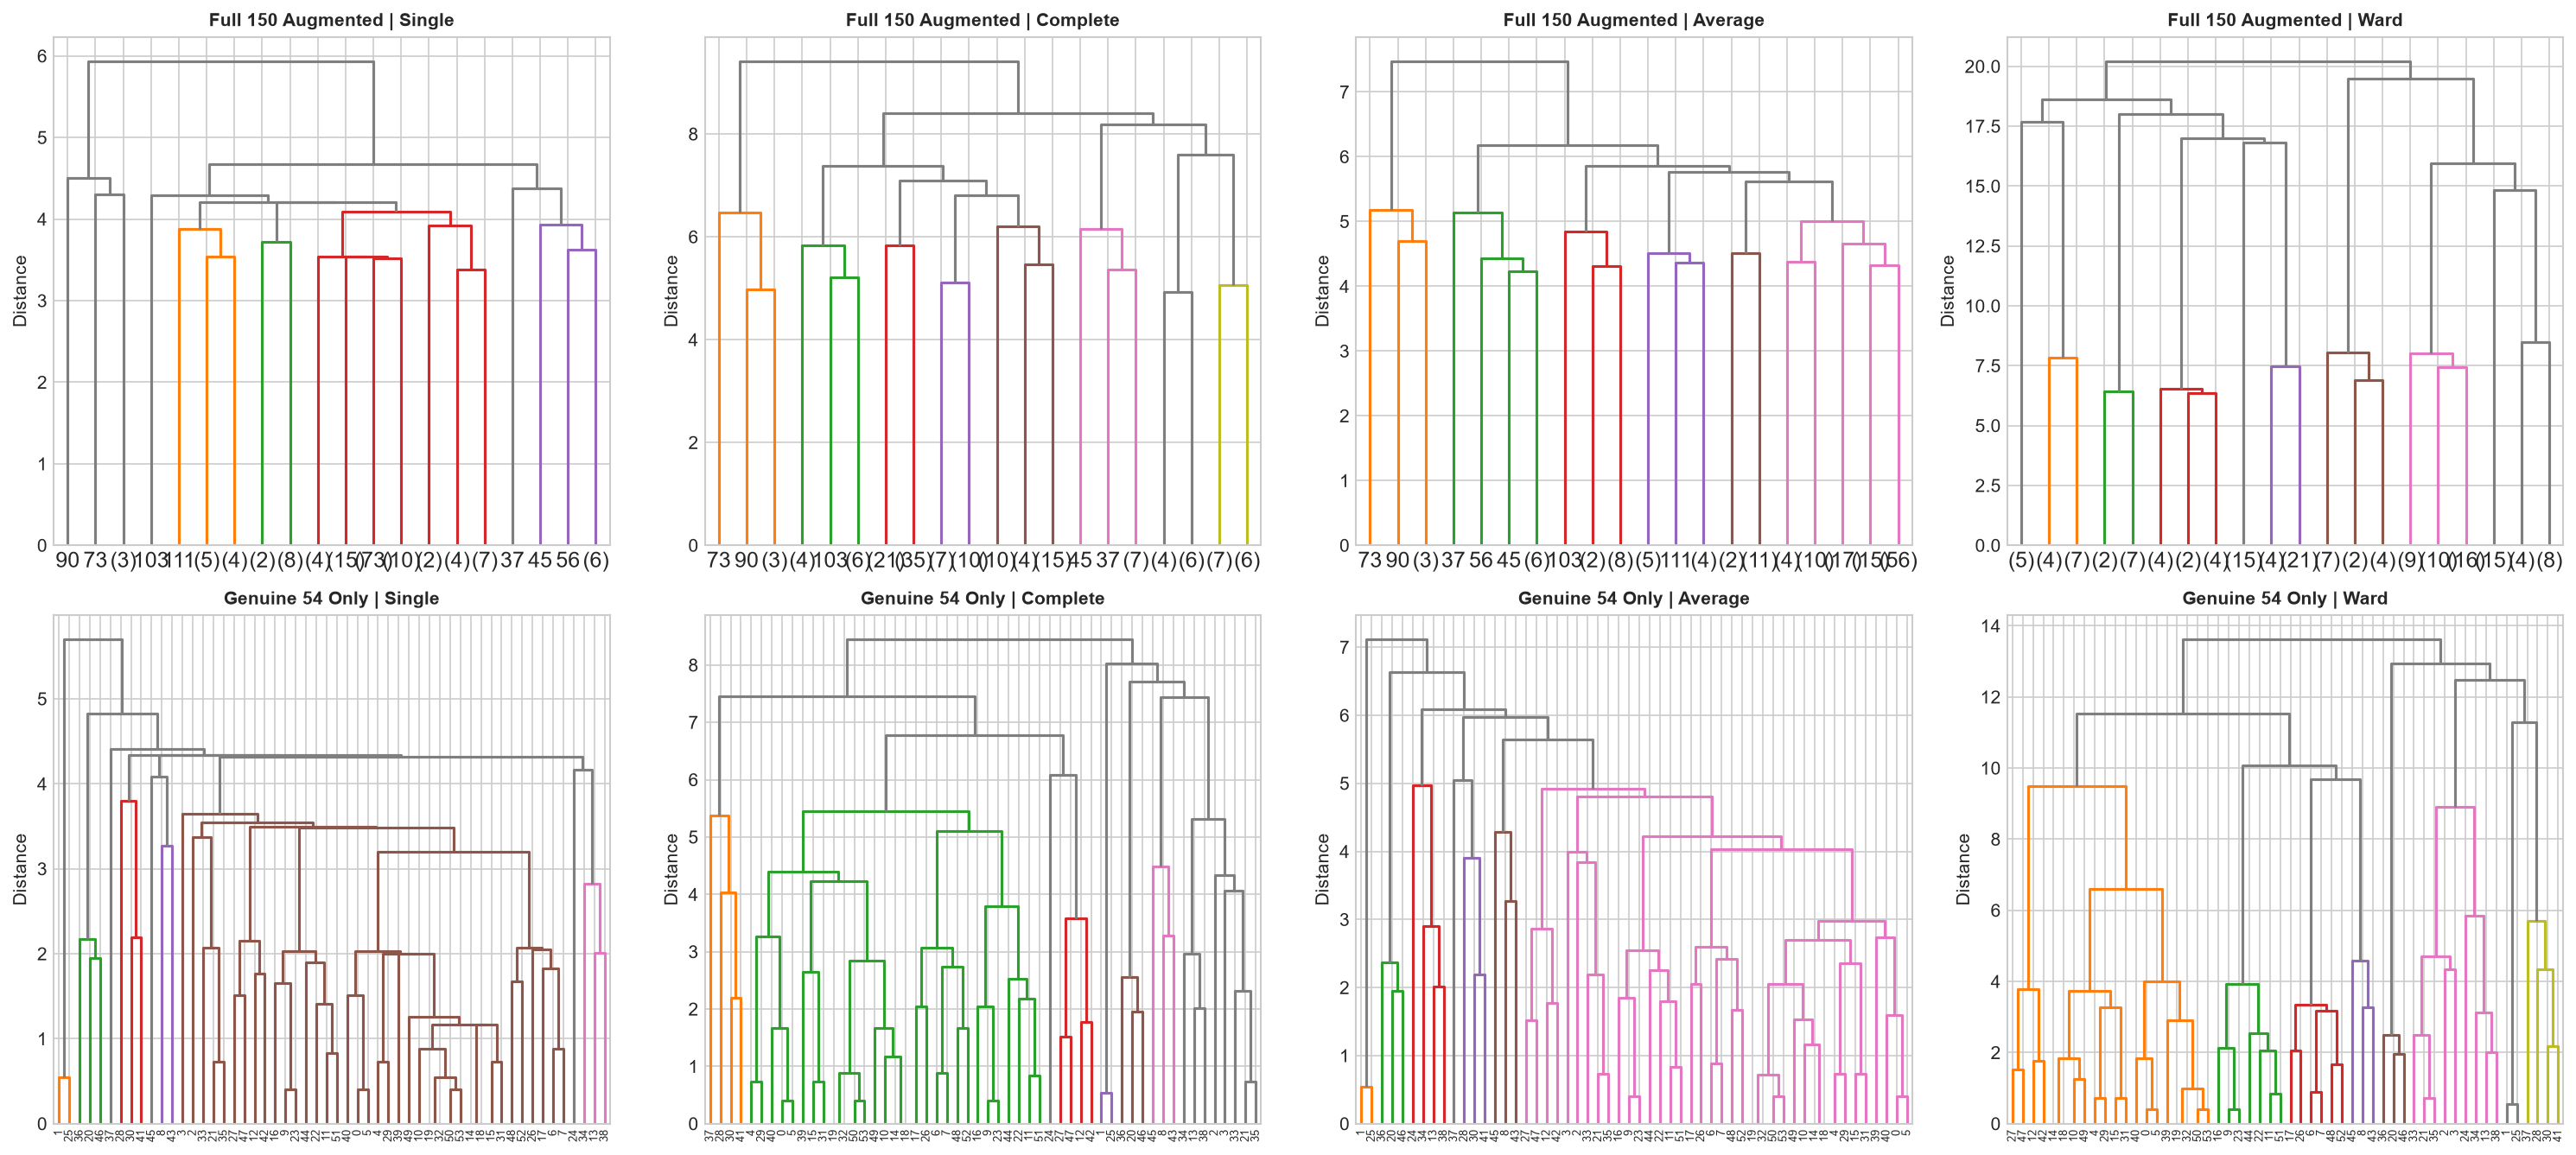

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for r_idx, (ds_name, df) in enumerate(datasets):
    X_sc = scaler.fit_transform(df[config_b])
    for c_idx, link in enumerate(['single', 'complete', 'average', 'ward']):
        ax = axes[r_idx, c_idx]
        Z = linkage(X_sc, method=link, metric='euclidean')
        dendrogram(Z, ax=ax, truncate_mode='lastp' if len(df) > 60 else None,
                   p=20 if len(df) > 60 else 30, show_leaf_counts=True,
                   color_threshold=0.7 * max(Z[:, 2]), above_threshold_color='#7f7f7f')
        ax.set_title(f"{ds_name} | {link.capitalize()}", fontsize=10, fontweight='bold')
        ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

In [8]:
# Agglomerative cluster size & dominant class breakdown (Full 150, K=3, Config B)
X_sc = scaler.fit_transform(df_150[config_b])
y_true = df_150['impact_category'].values
brk_rows = []
for link in ['single', 'complete', 'average', 'ward']:
    lbls = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_sc) + 1
    for cid in [1, 2, 3]:
        m = lbls == cid
        sub_y = pd.Series(y_true[m])
        cnts = {c: int((sub_y == c).sum()) for c in class_names}
        dom = max(cnts, key=cnts.get)
        brk_rows.append({
            'Linkage': link.capitalize(), 'Cluster': f"Cluster {cid}", 'Size': int(m.sum()),
            'Low': cnts['Low Impact'], 'Moderate': cnts['Moderate Impact'], 'High': cnts['High Impact'],
            'Dominant Class': dom, 'Dominant %': round(100 * cnts[dom] / m.sum(), 1)
        })
pd.DataFrame(brk_rows)

,Linkage,Cluster,Size,Low,Moderate,High,Dominant Class,Dominant %
0,Single,Cluster 1,5,1,1,3,High Impact,60.0
1,Single,Cluster 2,9,3,5,1,Moderate Impact,55.6
2,Single,Cluster 3,136,14,73,49,Moderate Impact,53.7
3,Complete,Cluster 1,32,7,16,9,Moderate Impact,50.0
4,Complete,Cluster 2,5,1,1,3,High Impact,60.0
5,Complete,Cluster 3,113,10,62,41,Moderate Impact,54.9
6,Average,Cluster 1,136,14,73,49,Moderate Impact,53.7
7,Average,Cluster 2,5,1,1,3,High Impact,60.0
8,Average,Cluster 3,9,3,5,1,Moderate Impact,55.6
9,Ward,Cluster 1,75,14,35,26,Moderate Impact,46.7


## 4. Phase VI Comparative Summary (KNN vs. K-Means vs. Agglomerative)

| Evaluation Criteria | KNN | K-Means | Agglomerative |
| :--- | :--- | :--- | :--- |
| **Learning type** | Supervised | Unsupervised | Unsupervised |
| **Labels used during fitting** | Yes (`impact_encoded`) | No (strictly excluded) | No (strictly excluded) |
| **Accuracy on held-out labels ($N=16$)** | 68.75% (Genuine Config B) / 62.50% (Augmented Config A; Baseline = 62.50%) | Not directly applicable | Not directly applicable |
| **Silhouette Score ($K=3$, Config B)** | Not applicable | 0.1904 (Full 150) / 0.2194 (Genuine 54) | Ward: 0.1499 (150) / 0.2298 (54); Single/Avg: 0.2491 (chaining) |
| **ARI / NMI (Full 150, $K=3$, Config B)** | Not applicable | ARI = 0.0061 / NMI = 0.0043 | Ward: ARI = 0.0177 / NMI = 0.0516; Complete: ARI = 0.0398 / NMI = 0.0250 |
| **Main observations** | Predicts majority (`Moderate`) and some `High`, but 0% recall on `Low Impact`; Config B genuine baseline performed best. | Composite features (Config B) gave better separation; clusters reflect usage/platform habits rather than impact tiers. | Single & Average linkages suffer severe chaining (`136/9/5`), whereas Ward yields balanced clusters (`75/62/13`). |
| **Limitations** | Tiny holdout ($N=16$), class imbalance, synthetic augmentation did not improve holdout generalization. | Moderate silhouette (~0.19–0.22); 21 boundary observations with negative silhouette; near-zero alignment with impact labels. | Sensitive to linkage choice; Ward avoids chaining but yields lower raw silhouette; low external label alignment. |

*Note:* Near-zero ARI/NMI measures low cluster–label alignment; target isolation is verified independently via feature-column inspection. Whether unobserved factors (e.g., self-discipline or study habits) explain why similar usage profiles yield different impact labels is a hypothesis for future research.